### Lab #2: Probability, Distributions, and Statistical Questions

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

### Problem 1
### In lecture and homework we explored how the convolution can be used to calculate the probability of a sum or average. For this problem we are going to imagine that we are looking for gamma-ray sources (e.g. with the Fermi telescope). In this kind of telescope there is a background of cosmic-rays (electrons and protons, mostly) that provides a discrete noise term across the sky that precisely follows a Poisson distribution. To detect a gamma-ray source, you need to ask what is the probability that the cosmic-ray background would have given you a measurement as signal-like or more than the signal that you received.

### To set up the problem, assume in 1 day the average cosmic-ray background is some number X (pick someting btwn 0.5 and 10, with different values for you and your lab partner); and the average number of gamma-rays emitted by your hypothetical source is Y (pick something larger than X).

### A) Show how the probability distribution of the background changes as you integrate (sum) for more days.

[1.35335283e-01 2.70670566e-01 2.70670566e-01 1.80447044e-01
 9.02235222e-02 3.60894089e-02 1.20298030e-02 3.43708656e-03
 8.59271640e-04 1.90949253e-04 3.81898506e-05 6.94360921e-06
 1.15726820e-06 1.78041262e-07 2.54344660e-08 3.39126213e-09
 4.23907766e-10 4.98715019e-11 5.54127799e-12 5.83292420e-13
 5.83292420e-14 5.55516590e-15 5.05015082e-16 4.39143550e-17
 3.65952958e-18 2.92762366e-19 2.25201820e-20 1.66816163e-21
 1.19154402e-22 8.21754499e-24 5.47836332e-25]


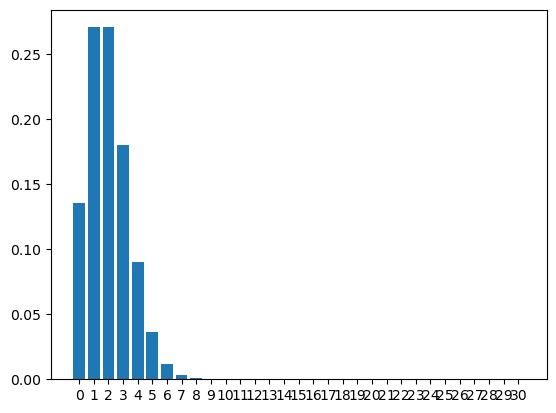

In [48]:
X=2 
Y=3
xaxis =np.arange(0,31) 
yaxis= stats.poisson.pmf(xaxis, mu=X) 
print(yaxis) 
fig, ax = plt.subplots(1, 1)
ax.bar(xaxis, yaxis) 
ax.set_xticks(xaxis)
plt.show()

### Background prduces an average of 2 counts per day and as more days are added, the total count distribution move larger counts. for n days, the total has mean 2n and sd sqrt(2n). Although the aboslute width increase, the wideth relative to mean decrease. 

### B) Show that after 5 days, the summed probability distribution is still a Poisson distribution. Explain why this makes sense from a mathematical and conceptual point of view.

yaxis10.shape=(61,)
yaxis10.shape=(91,)
yaxis10.shape=(121,)
yaxis10.shape=(151,)


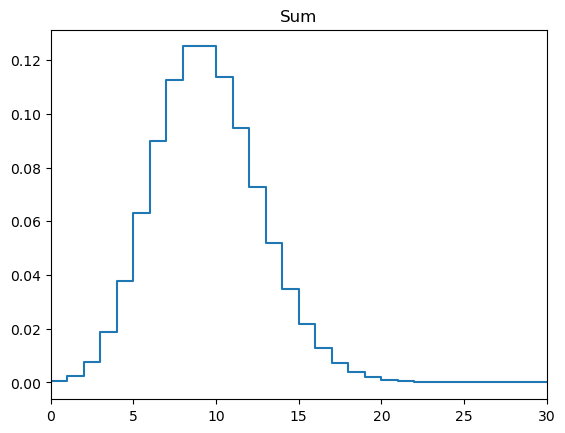

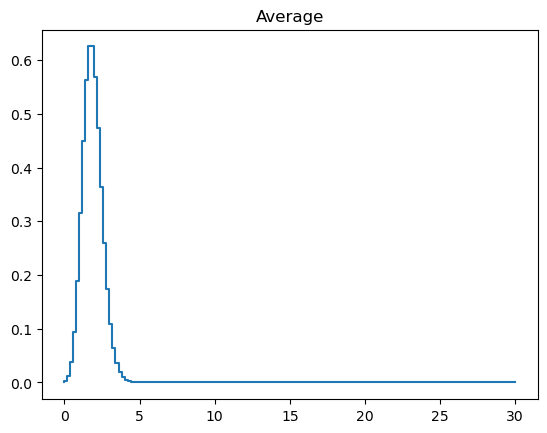

In [49]:
n =5 
yaxis10 = yaxis.copy() 
for i in range (n-1): 
    yaxis10 = np.convolve(yaxis10, yaxis, mode='full') 
    print(f"{yaxis10.shape=}")

xsum= np.arange(0,151) 
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1)
ax.step(xsum, yaxis10) 
ax.set_xlim(0,30) 
ax.set_xticks(np.arange(0,31,5))
plt.title("Sum")
plt.show()

fig, ax = plt.subplots(1, 1)
ax.step(xaverage, n*yaxis10) 
plt.title("Average")
plt.show() 

### Sum of independent Poisson random variables is also poisson, with mean equal to the sum of their means. In this case S5~ Poisson(5x) = Poisson(10) Therefore, after convolution, the result should agree with Poisson distribution with mean 10, and this result agrees with my graph. 

###C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

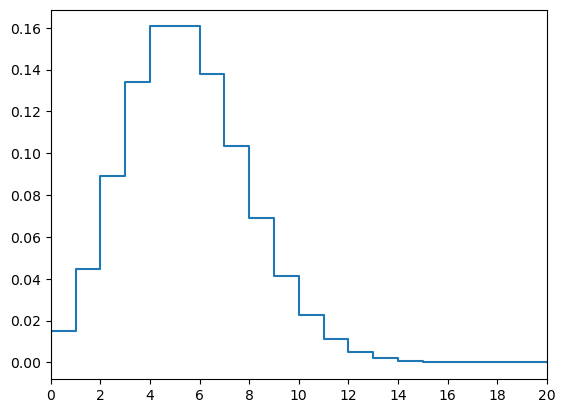

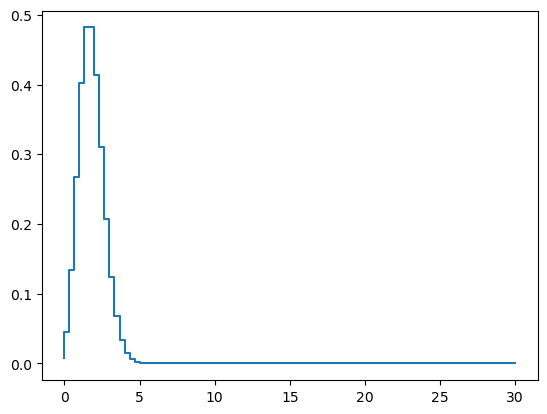

In [50]:
n =3
yaxis10 = yaxis.copy() 
for i in range (n-1): 
    yaxis10 = np.convolve(yaxis10, yaxis, mode='full') 

xsum = np.arange(len(yaxis10))
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1)
ax.step(xsum, yaxis10) 
ax.set_xlim(0, 20)
ax.set_xticks(np.arange(0, 21, 2))
plt.show()

fig, ax = plt.subplots(1, 1)
ax.step(xaverage, n*yaxis10) 
plt.show() 

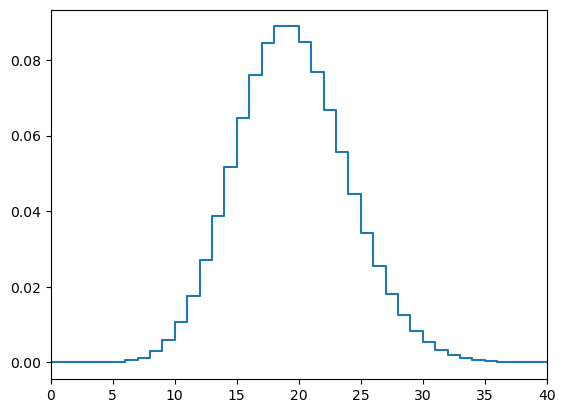

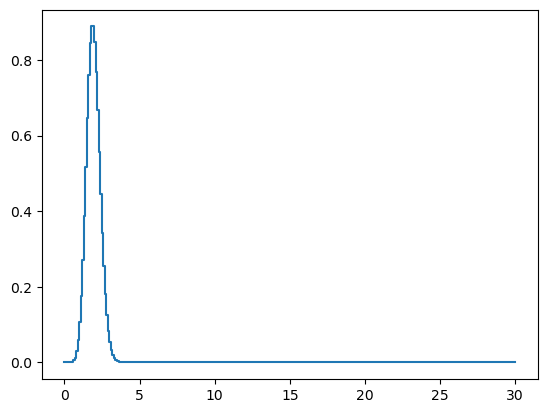

In [51]:
n =10
yaxis10 = yaxis.copy() 
for i in range (n-1): 
    yaxis10 = np.convolve(yaxis10, yaxis, mode='full') 

xsum = np.arange(len(yaxis10))
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1)
ax.step(xsum, yaxis10) 
ax.set_xlim(0, 40)
ax.set_xticks(np.arange(0, 41, 5))
plt.show()

fig, ax = plt.subplots(1, 1)
ax.step(xaverage, n*yaxis10) 
plt.show() 

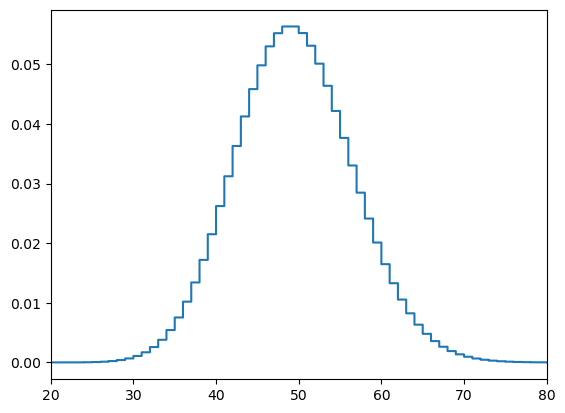

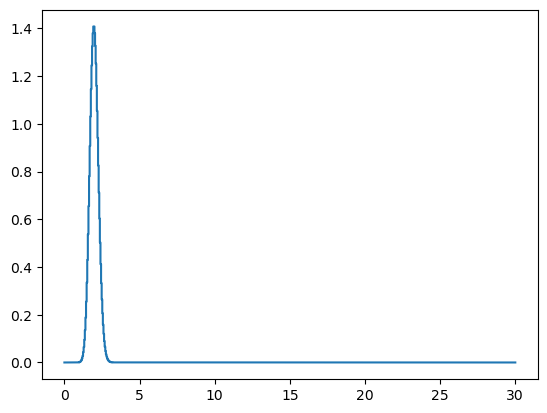

In [52]:
n =25
yaxis10 = yaxis.copy() 
for i in range (n-1): 
    yaxis10 = np.convolve(yaxis10, yaxis, mode='full') 

xsum= np.arange(0,751) 
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1)
ax.step(xsum, yaxis10) 
ax.set_xlim(20, 80)
ax.set_xticks(np.arange(20, 81, 10))
plt.show()

fig, ax = plt.subplots(1, 1)
ax.step(xaverage, n*yaxis10) 
plt.show() 

### for the daily average K bar is Sn/n, so E[K bar] =x =2, Var(Kbar) = X/n = 2/n. Thus averging more days keeps keeps the distrubtion centered at 2 and making it narrower. Its shape also become more symmetric and getting closer to Gaussian, which is consistent with central limit theorem. This is consistent with my graph, which looks like a Gaussian.The sum still remains Posisson, but the shape becomes gaussian as its mean increases.

### D) Pick some number of days N, and assume you saw Y*N gamma rays from your source. Calculate the 'sigma' of your observation. [In reality the number of gamma-rays seen from a source will also fluctuate, but we're going to ignore that complication for a couple of labs.]

In [53]:
N =3
w = Y * N 
m= stats.poisson.cdf(w-1, mu=2*N)
sigma = stats.norm.ppf(m, loc =0, scale = 1) 
print(sigma, m) 

1.0246570997086928 0.8472374939845612


### I pick N=3, and converted background probability into a sigificance around 1.02 signma. 

### Problem 2
### Pick a skewed continuous distribtuion, such as a Rayleigh, that describes your background over some observing interval.
### A) Show how the distribution changes as you average over more observing intervals.

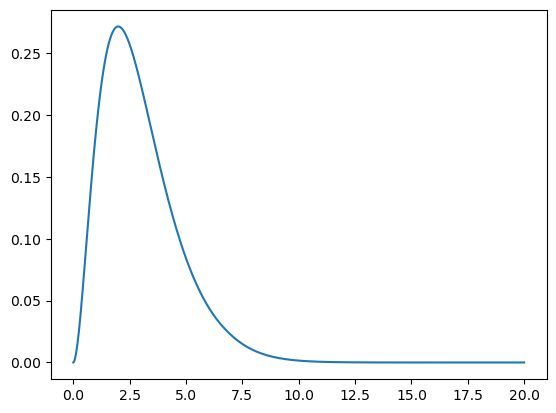

In [54]:
n=3
x = np.linspace(0,20,2001) 
dx = x[1] - x[0] 
p = stats.expon.pdf(x, loc=0, scale=3)  
p=p/np.sum(p) # convert number into proabilities over x linspace 
yaxis=p.copy()

for i in range (n-1): 
    yaxis = np.convolve(yaxis, p, mode='full') 
xsum = np.linspace(n*x[0], n*x[-1], len(yaxis)) # x[0] first value , x[-1] last value create. lens(yaxis) correspond position for yaxis
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1)
ax.plot(xaverage, n*yaxis/dx) 
plt.show() 

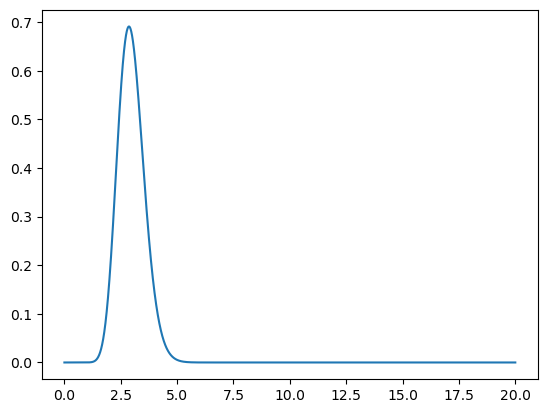

In [55]:
n=25
x = np.linspace(0,20,2001) 
dx = x[1] - x[0] 
p = stats.expon.pdf(x, loc=0, scale=3)  
p=p/np.sum(p) # convert number into proabilities over x linspace 
yaxis=p.copy()

for i in range (n-1): 
    yaxis = np.convolve(yaxis, p, mode='full') 
xsum = np.linspace(n*x[0], n*x[-1], len(yaxis)) # x[0] first value , x[-1] last value create. lens(yaxis) correspond position for yaxis
xaverage = xsum/n # rescale 

fig, ax = plt.subplots(1, 1)
ax.plot(xaverage, n*yaxis/dx) 
plt.show() 

### B) Discuss how the shape changes. Does it approach a Gaussian distribution? If yes, after how many intervals? I choose exponential distribution with scale 3. at 3 intervals the average, the average distrubtion remains very right skewed. at 25 intervals, it is narrower and closer to a gaussian. This behavior agrees with central limit theorem. I don't think there is eact finite number of intervals in which the distrubtion becomes Gaussian. The more intervals you use, the closer you get to the Gaussian distribution. 

### Problem 3
### The discovery of optical/infra-red counterparts of Neutron star mergers initially detected with gravity-waves is one of the great discoverys in the last few years (wikipedia, scientific paper), and has ushered in the age of "multi-messenger astrophysics." The science that can be done by matching a gravity-wave signal (directly measures the mass of the neutron stars and their distance) with the optical emisson (redshift, nuclear astrophysics of the resulting explosion) is staggering. Lots of science from how the heaviest elements are formed to constraints on Dark Energy.

### We're going to explore one of the analysis questions that comes up when looking for the optical counterparts (a new optical source) of a gravity wave signal. For this problem let's assume that we are using an optical telescope with a thermal noise background from the CCD (dark current, particularly an issue with older CCDs and/or infra-red CCDs). After flat-fielding, the background appears as a zero-mean Gaussian with constant width over the image.

### Version 1
### You have an alert from LIGO that is also seen in with the X-ray/ultra-violet satellite SWIFT. SWIFT gives you a very precise location, so you take an image of that part of the sky. But because of SWIFT's accuracy, you know which pixel in your image to look for a counterpart in.

### A) From looking at all the other pixels in your image, you can measure the width of the background Gaussian distribution X (pick something). Assuming you see a signal of strength Y (pick a floating-point number; typical optical CCDs are not sensitive enough to count photons so the readings are floating point brightnesses, not integer photons). Calculate the significance of your detection. Can you claim a discovery (traditionally 5-sigma or more)?

In [56]:
Width_x = 10 
Y =55.6
p = stats.norm.sf(Y, loc=0, scale = Width_x) 
z = stats.norm.isf(p) 
print(p)
print(z) 

1.348873251527836e-08
5.5600000000000005


### The background brightness is Gaussian with mean at 0 and standard deviation 10 that I chose. For brightness Y =55.6 I chose, the significance is 5.56 sigma. since this exceeds the conventional 5 sigma threshold, we can claimed a discovery 

### Version 2
### You have an alert from LIGO, but no associated detection from SWIFT. This could be because it is a black hole-black hole merger, a black hole-neutron star merger (neither seem to emit X-rays or UV light), or it could because SWIFT was indisposed at the time (wrong side of the earth in its orbit). Whatever the cause, you know what region of the sky to look in, but not which pixel.

### B) If you have to look for a signal in 10k pixels, what is the probability distribution of your background? (Clearly state the statistical question, then turn that into math using your background distribution from part 1 of this problem.)

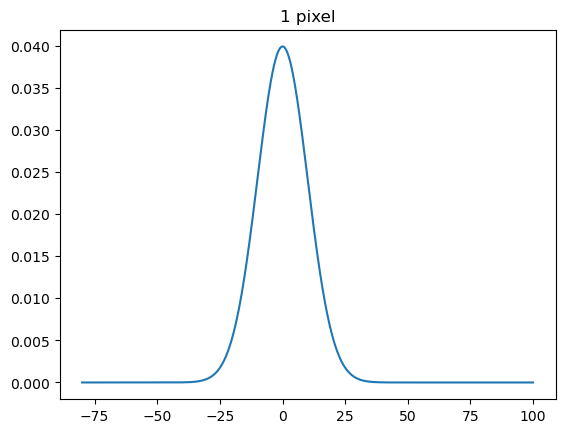

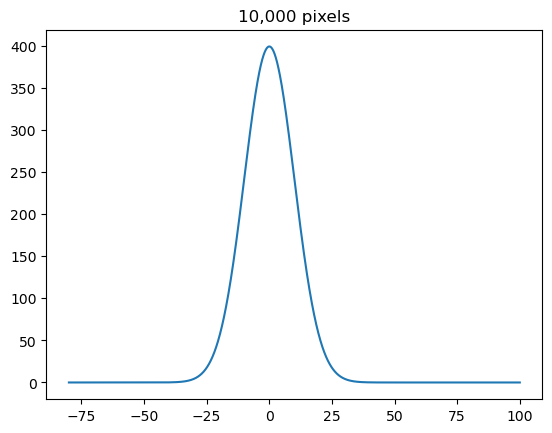

In [57]:
N =10000 
b = np.linspace(-80,100,2000) 
f = stats.norm.pdf( b, loc=0, scale = Width_x) 
plt.figure()
plt.title("1 pixel")
plt.plot(b,f) 

plt.figure()
plt.title("10,000 pixels")
plt.plot(b, N*f, label = "10000 pixels")
plt.show() 

### statistical question: what's the probability that at least one of 10000 background pixels has brightness 55.6 or higher? 
### The scale curve has total area 10000, so it represents expected count density instead of a normalized pdf. f(b) is single pixel background PDF, the expected count density across 10,000 pixels is 10000f(b). The two graphs has the same width, but the expected counts is increased by a factor of 10,000. for rare events, the probability of at least one exceedance is approximately 10,000p, which is much larger than just one pixel. 

### C) Taking your brightest candidate signal from the region (assume it has the same signal as in part 1), calculate the significance of your detection.

In [58]:
p_Whole = N * p 
z_Whole = stats.norm.isf(p_Whole) 
print("probability after 10000 pixels searches :", p_Whole) 
print("signifance of the brightest:", z_Whole) 

probability after 10000 pixels searches : 0.0001348873251527836
signifance of the brightest: 3.642717699852486


### after applying trials, the significance drops from 5.56 sigma to 3.64 sigma. therefore, searching more pixels allows background to have a higher likehood to produce a rare bright fluctuation, so observation become less significant and no longer meets 5 sigma discovery threshold. 